In [1]:
# ! python -m pip install "numpy==1.23.5" "matplotlib==3.7.5" "ipython==8.18.1" "ipympl==0.9.4"

In [2]:
%matplotlib widget

In [3]:
import numpy as np 
from dezero import Variable
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.animation import FuncAnimation
## python -m pip install numpy==1.23.5 matplotlib==3.7.5 ipympl

In [4]:
# 로젠브록 함수 생성
def rosenbrock(x0, x1):
    # 로젠브록 함수 계산
    y = 100 * (x1 - x0**2)**2 + (x0 - 1)**2
    return y

In [5]:
# x축과 y축의 값 생성
x0_vals = np.linspace(-2.0, 2.0, num=250)
x1_vals = np.linspace(-1.0, 3.0, num=250)

# 격자점 생성
x0_grid, x1_grid = np.meshgrid(x0_vals, x1_vals)

# z축 값 계산
y_grid = rosenbrock(x0_grid, x1_grid)

# 로그를 취한 최솟값과 최댓값 구하기
y_log10_min = np.floor(np.log10(y_grid.min()) - 1.0)
y_log10_max = np.ceil(np.log10(y_grid.max()) + 1.0)

# 등고선 값을 생성
lev_log10 = np.linspace(y_log10_min, y_log10_max, num=45)[25:35]
levs = np.power(10, lev_log10)

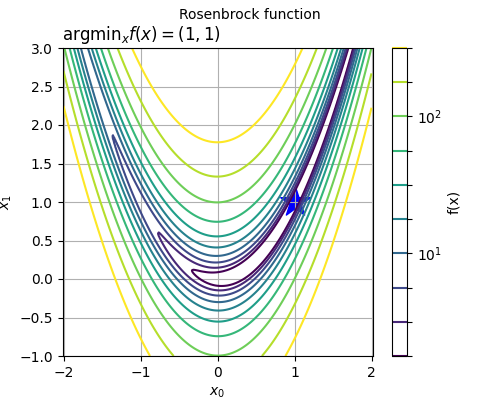

In [7]:
# 로젠브록 함수의 등고선도 작성
plt.figure(figsize=(5, 4), facecolor='white')
cnt = plt.contour(x0_grid, x1_grid, y_grid,
                  norm=LogNorm(), levels=levs)  # 등고선
plt.scatter(1.0, 1.0,
            marker='*', s=500, c='blue')  # 최솟값
plt.xlabel('$x_0$', fontsize=10)
plt.ylabel('$x_1$', fontsize=10)
plt.suptitle('Rosenbrock function', fontsize=10)
plt.title('$\mathrm{argmin}_x f(x) = (1, 1)$', loc='left')
plt.colorbar(cnt, label='f(x)')
plt.grid()
plt.axis('equal')
plt.show()

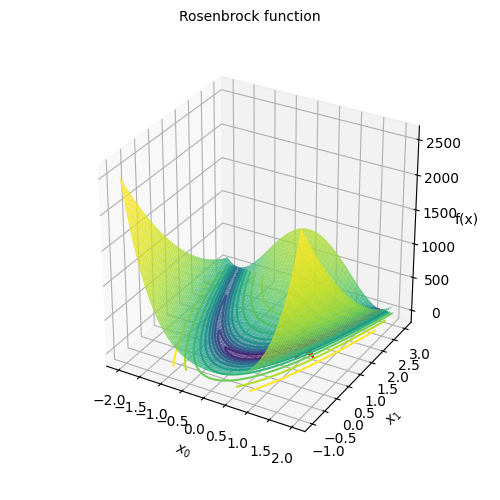

In [20]:
# 로젠브록 함수의 곡면도 작성
fig = plt.figure(figsize=(5, 5), facecolor='white')
ax = fig.add_subplot(projection='3d')  # 3D 설정
ax.contour(x0_grid, x1_grid, y_grid,
           norm=LogNorm(), levels=levs, offset=0.0)  # 등고선
ax.plot_surface(x0_grid, x1_grid, y_grid,
                norm=LogNorm(), cmap='viridis', alpha=0.8)  # 곡면
ax.scatter(1.0, 1.0, rosenbrock(1.0, 1.0),
           marker='*', s=500, c='red')  # 최솟값
ax.set_xlabel('$x_0$', fontsize=10)
ax.set_ylabel('$x_1$', fontsize=10)
ax.set_zlabel('f(x)', fontsize=10)
fig.suptitle('Rosenbrock function', fontsize=10)
ax.set_box_aspect(aspect=(1, 1, 1))
plt.show()

In [10]:
# 초기값 설정
x0 = Variable(np.array(0.0))
x1 = Variable(np.array(2.0))

# 학습률 설정
lr = 0.001

# 반복 횟수 설정
iters = 10000

# 학습 과정 기록용 리스트 초기화
trace_x0 = [x0.data.copy()]
trace_x1 = [x1.data.copy()]

# 반복 학습
for i in range(iters):
    # 로젠브록 함수의 순전파 계산
    y = rosenbrock(x0, x1)
    
    # 기울기 초기화
    x0.cleargrad()
    x1.cleargrad()
    
    # 역전파로 기울기 계산
    y.backward()
    
    # 경사하강법으로 값 업데이트
    x0.data -= lr * x0.grad.data
    x1.data -= lr * x1.grad.data
    
    # 업데이트된 값 저장
    trace_x0.append(x0.data.copy())
    trace_x1.append(x1.data.copy())
    
    # 일정 횟수마다 값 출력
    if (i+1) % 500 == 0:
        print(
            'iter ' + str(i+1) + 
            ': x=(' + str(np.round(x0.data, 3)) + 
            ', ' + str(np.round(x1.data, 3)) + ')'
        )

iter 500: x=(0.529, 0.277)
iter 1000: x=(0.684, 0.466)
iter 1500: x=(0.77, 0.592)
iter 2000: x=(0.826, 0.682)
iter 2500: x=(0.866, 0.749)
iter 3000: x=(0.895, 0.8)
iter 3500: x=(0.917, 0.84)
iter 4000: x=(0.933, 0.871)
iter 4500: x=(0.947, 0.896)
iter 5000: x=(0.957, 0.916)
iter 5500: x=(0.965, 0.932)
iter 6000: x=(0.972, 0.944)
iter 6500: x=(0.977, 0.955)
iter 7000: x=(0.981, 0.963)
iter 7500: x=(0.985, 0.97)
iter 8000: x=(0.988, 0.975)
iter 8500: x=(0.99, 0.98)
iter 9000: x=(0.992, 0.984)
iter 9500: x=(0.993, 0.987)
iter 10000: x=(0.994, 0.989)


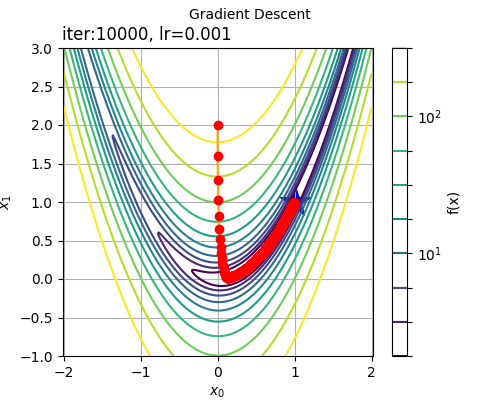

In [19]:
# 등고선도 생성
plt.figure(figsize=(5, 4), facecolor='white')
cnt = plt.contour(x0_grid, x1_grid, y_grid,
                  norm=LogNorm(), levels=levs)  # 등고선
plt.scatter(1.0, 1.0,
            marker='*', s=500, c='blue')  # 최솟값
plt.plot(trace_x0, trace_x1,
         c='orange', marker='o', mfc='red', mec='red')  # 갱신값의 변화
plt.xlabel('$x_0$', fontsize=10)
plt.ylabel('$x_1$', fontsize=10)
plt.suptitle('Gradient Descent', fontsize=10)
plt.title('iter:' + str(iters) + ', lr=' + str(lr), loc='left')
plt.colorbar(cnt, label='f(x)')
plt.grid()
plt.axis('equal')
plt.show()

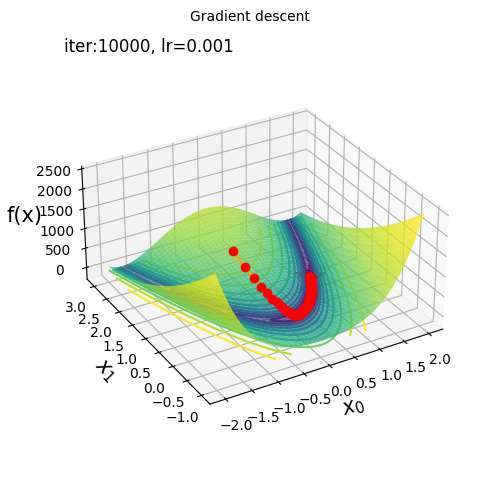

In [18]:
# 갱신값의 z축 값을 계산
trace_y = rosenbrock(np.array(trace_x0), np.array(trace_x1))

# 표시할 z축 최대값과 곡면 마스크 생성
z_max = float(np.nanmax(y_grid))
y_mask_grid = np.ma.masked_invalid(y_grid)

# 로젠브록 함수의 곡면도 작성
fig = plt.figure(figsize=(5, 5), facecolor='white')
ax = fig.add_subplot(projection='3d')  # 3D 설정
ax.contour(x0_grid, x1_grid, y_grid,
           norm=LogNorm(), levels=levs, offset=0.0, zorder=0)  # 등고선
ax.plot_surface(x0_grid, x1_grid, y_mask_grid,
                norm=LogNorm(), cmap='viridis', alpha=0.8, zorder=1)  # 곡면
ax.scatter(1.0, 1.0, rosenbrock(1.0, 1.0),
           marker='*', s=500, c='red')  # 최솟값
ax.plot(trace_x0, trace_x1, trace_y,
        c='orange', marker='o', mfc='red', mec='red', zorder=15)  # 갱신값의 변화
ax.set_xlabel('$x_0$', fontsize=15)
ax.set_ylabel('$x_1$', fontsize=15)
ax.set_zlabel('f(x)', fontsize=15)
ax.set_title('iter:' + str(iters) + ', lr=' + str(lr), loc='left')
fig.suptitle('Gradient descent', fontsize=10)
ax.set_box_aspect(aspect=(1, 1, 0.5))
ax.set_zlim(-z_max * 0.1, z_max)
ax.view_init(elev=30, azim=240)
plt.show()

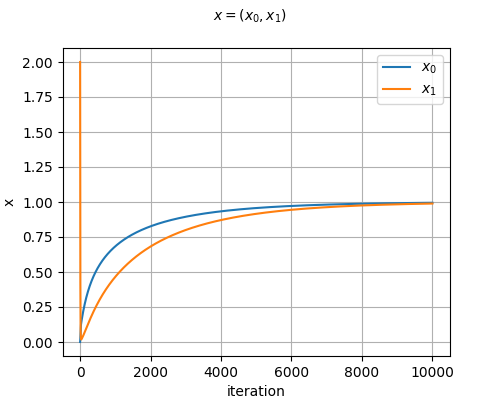

In [17]:
# 업데이트 값의 변화를 그래프로 표시
plt.figure(figsize=(5, 4), facecolor='white')
plt.plot(np.arange(iters+1), trace_x0, label='$x_0$')
plt.plot(np.arange(iters+1), trace_x1, label='$x_1$')
plt.xlabel('iteration')
plt.ylabel('x')
plt.suptitle('$x = (x_0, x_1)$', fontsize=10)
plt.legend()
plt.grid()
plt.show()